# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [1]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
149 115


## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
price_A, price_B = 25.0, 30.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")


$25: n = 118, p_hat = 0.398, r_hat = 9.96
$30: n = 192, p_hat = 0.391, r_hat = 11.72


In [ ]:
rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)


,price,r_hat,SE (bootstrap),SE (formula)
0,85.0,18.563,2.680,2.662
1,90.0,14.911,2.604,2.574


In [ ]:
# 95% bootstrap confidence intervals

def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])


,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,85.0,174,18.56,"(13.68, 23.94)","(13.35, 23.78)"
1,90.0,169,14.91,"(10.12, 20.24)","(9.87, 19.96)"


In [ ]:

# Difference in estimated revenue
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

r_25 - r_30 = 3.65
  95% CI, bootstrap: (-3.67, 10.76)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-3.61, 10.91)  ->  can't tell (interval contains 0)


Both intervals include 0, so we can't tell which is better. We need to collect more data to see the difference.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(5030)

# practice only: the practice market. In the lab, `from demand import demand` replaces everything below.

# practice demand curve
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

def practice_demand(price):
    """One practice market test. Returns 1s and 0s, one per customer (about 180 customers)."""
    return sales(price, mean_customers=rng.gamma(45.0, 4.0), rng=rng)

In [ ]:
# Second market test at each price
pool_A = np.concatenate([resp_A, demand(price_A)])
pool_B = np.concatenate([resp_B, demand(price_B)])
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_A, price_A, pool_reps_A, pool_B, price_B, pool_reps_B)
print(f"pooled r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

SE ratio (pooled / one test), bootstrap: $25: 0.70, $30: 0.68;  1/sqrt(2) = 0.71
pooled r_20 - r_25 = -2.90
  95% CI, bootstrap: (-4.80, -0.85)  ->  $25 earns more
  95% CI, formula:   (-4.88, -0.91)  ->  $25 earns more


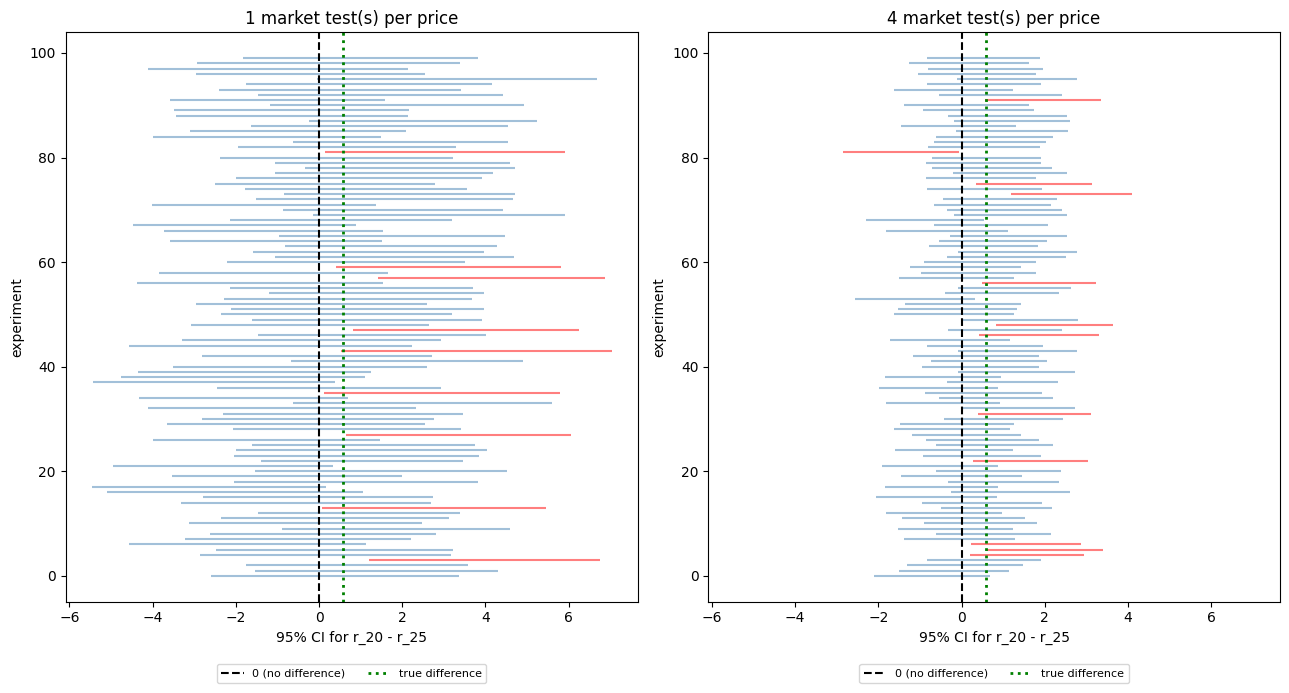

In [ ]:
def one_experiment(k):
    """Pool k market tests at each price and return the 95% CI for r_A - r_B."""
    a = np.concatenate([practice_demand(price_A) for _ in range(k)])
    b = np.concatenate([practice_demand(price_B) for _ in range(k)])
    d = price_A * a.mean() - price_B * b.mean()
    se = np.sqrt(se_formula(a, price_A) ** 2 + se_formula(b, price_B) ** 2)
    return d - 1.96 * se, d + 1.96 * se

true_diff = price_A * purchase_probability(price_A) - price_B * purchase_probability(price_B)

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True)
for ax, k in zip(axes, [1, 4]):
    CIs = np.array([one_experiment(k) for _ in range(100)])
    for i, (lo, hi) in enumerate(CIs):
        ax.hlines(i, lo, hi, color="steelblue" if lo <= 0 <= hi else "red", alpha=0.5, linewidth=1.5)
    ax.axvline(0, color="black", linestyle="--", label="0 (no difference)")
    ax.axvline(true_diff, color="green", linestyle=":", linewidth=2, label="true difference")
    ax.set(title=f"{k} market test(s) per price", xlabel="95% CI for r_20 - r_25", ylabel="experiment")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
rows = []
for k in [1, 2, 4, 8]:
    CIs = np.array([one_experiment(k) for _ in range(1000)])
    rows.append({
        "market tests per price": k,
        "total tests": 2 * k,
        "power": np.mean((CIs[:, 0] > 0) | (CIs[:, 1] < 0)),
        "coverage": np.mean((CIs[:, 0] <= true_diff) & (true_diff <= CIs[:, 1])),
        "average CI width": np.mean(CIs[:, 1] - CIs[:, 0]),
    })
print(f"true r_20 - r_25: {true_diff:.2f}")
pd.DataFrame(rows).round(3)

true r_20 - r_25: 0.58


,market tests per price,total tests,power,coverage,average CI width
0,1,2,0.083,0.946,5.582
1,2,4,0.099,0.942,3.932
2,4,8,0.144,0.948,2.779
3,8,16,0.212,0.946,1.965


For quesiton 8, since we double the sample size, our SE should shrink by a factor of square root of 2. The equation is 1 over sqaure root n. For question 9, yes it was worth resampling since our confidence interval in part 1 for the difference in revenue contained 0. This resampling produced confidence intervals that did not contain 0, which allows us to draw a real conclusion about the pricing revenue.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

In [3]:

rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap estimates of revenue per potential customer."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """Standard error using the formula from the lab."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

def ci_table(pairs):
    rows = []
    for price, responses, reps in pairs:
        r_hat = price * responses.mean()
        se = se_formula(responses, price)
        lo, hi = np.percentile(reps, [2.5, 97.5])

        rows.append({
            "price": price,
            "n": len(responses),
            "p_hat": round(responses.mean(), 3),
            "r_hat": round(r_hat, 2),
            "SE": round(se, 3),
            "95% CI": f"({lo:.2f}, {hi:.2f})"
        })

    return pd.DataFrame(rows)


In [4]:
import pandas as pd

# Initial exploration across the price range
prices = [5, 20, 35, 50, 65, 80, 100]

results = {}

for price in prices:
    responses = np.asarray(demand(price=float(price)))
    results[price] = responses

# Bootstrap each price and summarize the results
reps = {
    price: bootstrap_r(responses, price)
    for price, responses in results.items()
}

initial_table = ci_table([
    (price, results[price], reps[price])
    for price in prices
])

print(initial_table.to_string(index=False))
print("Market tests used:", len(results))


 price   n  p_hat  r_hat    SE         95% CI
     5 165  0.952   4.76 0.084   (4.58, 4.91)
    20 180  0.444   8.89 0.741  (7.44, 10.33)
    35 124  0.290  10.16 1.427  (7.34, 12.98)
    50 146  0.308  15.41 1.911 (11.64, 19.19)
    65 177  0.277  17.99 2.186 (13.59, 22.40)
    80 203  0.182  14.58 2.168 (10.25, 18.92)
   100 184  0.027   2.72 1.199   (0.54, 4.89)
Market tests used: 7


In [6]:
price_A, price_B = 35.0, 65.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")


$35: n = 231, p_hat = 0.390, r_hat = 13.64
$65: n = 142, p_hat = 0.303, r_hat = 19.68


In [7]:
rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,35.0,13.636,1.106,1.123
1,65.0,19.683,2.474,2.506


In [8]:
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,35.0,231,13.64,"(11.51, 15.76)","(11.44, 15.84)"
1,65.0,142,19.68,"(14.65, 24.26)","(14.77, 24.60)"


In [10]:
# Difference in estimated revenue
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$35', '$65')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$35', '$65')}")

r_75 - r_80 = -6.05
  95% CI, bootstrap: (-11.37, -0.86)  ->  $65 earns more
  95% CI, formula:   (-11.43, -0.66)  ->  $65 earns more


In [ ]:
prices = [60, 65, 75, 80, 87, 92, 97]

results = {}

for price in prices:
    responses = np.asarray(demand(price=float(price)))
    results[price] = responses

# Bootstrap each price and summarize the results
reps = {
    price: bootstrap_r(responses, price)
    for price, responses in results.items()
}

initial_table = ci_table([
    (price, results[price], reps[price])
    for price in prices
])

print(initial_table.to_string(index=False))
print("Market tests used:", len(results))

 price   n  p_hat  r_hat    SE         95% CI
    60 149  0.268  16.11 2.178 (12.07, 20.54)
    65 179  0.223  14.53 2.024 (10.88, 18.52)
    75 168  0.292  21.88 2.630 (16.96, 27.23)
    80 164  0.238  19.02 2.660 (14.15, 24.39)
    87 173  0.185  16.09 2.568 (11.06, 21.12)
    92 192  0.156  14.38 2.411 (10.06, 19.17)
    97 147  0.061   5.94 1.918   (2.64, 9.90)
Market tests used: 7


In [ ]:
price_A, price_B = 75.0, 80.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")


$75: n = 162, p_hat = 0.265, r_hat = 19.91
$80: n = 202, p_hat = 0.257, r_hat = 20.59


In [ ]:
rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,75.0,19.907,2.678,2.602
1,80.0,20.594,2.557,2.461


In [ ]:
# 95% bootstrap confidence intervals

def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,75.0,162,19.91,"(14.81, 25.46)","(14.81, 25.01)"
1,80.0,202,20.59,"(15.84, 25.74)","(15.77, 25.42)"


In [ ]:
# Difference in estimated revenue
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_75 - r_80 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$75', '$80')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$75', '$80')}")

r_20 - r_25 = -0.69
  95% CI, bootstrap: (-7.69, 6.92)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-7.71, 6.33)  ->  can't tell (interval contains 0)


In [ ]:
price_A, price_B = 80.0, 85.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")


$80: n = 119, p_hat = 0.202, r_hat = 16.13
$85: n = 185, p_hat = 0.243, r_hat = 20.68


In [ ]:
rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,80.0,16.134,2.963,2.943
1,85.0,20.676,2.647,2.681


In [ ]:
# 95% bootstrap confidence intervals

def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,80.0,119,16.13,"(10.08, 22.18)","(10.37, 21.90)"
1,85.0,185,20.68,"(15.62, 25.73)","(15.42, 25.93)"


In [ ]:
# Difference in estimated revenue
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_80 - r_85 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$80', '$85')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$80', '$85')}")

r_20 - r_25 = -4.54
  95% CI, bootstrap: (-12.43, 2.96)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-12.34, 3.26)  ->  can't tell (interval contains 0)


In [ ]:
price_A, price_B = 85.0, 90.0
resp_A = demand(price_A)
resp_B = demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")

$85: n = 174, p_hat = 0.218, r_hat = 18.56
$90: n = 169, p_hat = 0.166, r_hat = 14.91


In [ ]:
rng = np.random.default_rng(5030)
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,85.0,18.563,2.680,2.662
1,90.0,14.911,2.604,2.574


In [ ]:
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,85.0,174,18.56,"(13.68, 23.94)","(13.35, 23.78)"
1,90.0,169,14.91,"(10.12, 20.24)","(9.87, 19.96)"


In [ ]:
# Difference in estimated revenue
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_85 - r_90 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$85', '$90')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$85', '$90')}")

r_20 - r_25 = 3.65
  95% CI, bootstrap: (-3.67, 10.76)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-3.61, 10.91)  ->  can't tell (interval contains 0)


Now find the price that maximizes revenue per customer. Search prices between about  5and 100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. Use as few market tests as you can (<25 would be good). Your grade will be based on, in this order, whether you:

accurately used the information you have by accurately interpreting confidence intervals
found a good price, close to the optimal price
and used fewer tests.
If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

Hints
Before you run any tests, write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

Deliverable: A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for  r  at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.






Our strategy was to find the optimal price by first testing a wide variety of prices, and then narrowing our search based on the results. Therefore, we started our tests at \$5 and increased the test prices in intervals of \$15. Based on the results from that, we saw \$65 and
\$80 had the highest estimated revenue, so we tested \$35 and $65 to see if there was a signficant difference in amount of revenue generated and there was. From there, we wanted to test in that range. We then ran another test with prices ranging from \$60 to \$97. These results showed us that our highest revenue was likely being generated from prices between 75 to 87. We then compared 2 potential optimal prices at a time within that range to see if there was enough evidence that one price generated more revenue than another. In total, we conducted 22 market tests.

In our narrowed tests, we started with \$75 and \$80. \$80 had a slightly lower standard error, and slightly higher values in its confidence interval, suggesting a higher estimated revenue with a more precise estimate. However, there wasn't enough evidence to  conclude if it was a significantly better price than \$75. We then moved to testing \$80 vs \$85, and we observed \$85 having a slightly lower standard error, and higher estimated revenue, but when comparing their differences, there still wasnt enough evidence to prove a price generates a signficant amount more revenue than the other price. Lastly, we compared \$85 and \$90, and \$85 again has higher estimated values in its confidence interval. We decided to end the testing here to save resources since our range of values with the highest confidence intervals couldn't be differentiated to be the optimal price. We would give \$85 as our best recommended price based on our results of consistent high revenue estimates and kept a lower standard error in comparison to others. In its last test, our 95% confidence interval for r_hat was (13.35, 23.78), and our interval for the difference was (−3.67, 10.76). To conclude with a price that generates signfiicantly more revenue than the others, we would need more data and more tests.
